In [1]:
# Upload files: Results from script execution (Executed in Barkla HPC)
# Files: cleaned_fx_data.csv, walk_forward_results.csv, detailed_metrics.csv, predictions.pkl
from google.colab import files
uploaded = files.upload()


Saving cleaned_fx_data.csv to cleaned_fx_data.csv
Saving detailed_metrics.csv to detailed_metrics (1).csv
Saving fx_project.py to fx_project.py
Saving predictions.pkl to predictions (1).pkl
Saving walk_forward_results.csv to walk_forward_results (1).csv


In [2]:
# Importing libraries & file loading
import pandas as pd
import numpy as np
import pickle
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score

wf = pd.read_csv("walk_forward_results.csv")
dm = pd.read_csv("detailed_metrics.csv")
with open("predictions.pkl", "rb") as f:
    preds_data = pickle.load(f)

data = pd.read_csv("cleaned_fx_data.csv", header=[0, 1], index_col=0, parse_dates=True)
print(data.shape)
print(wf.shape, dm.shape)

(1563, 35)
(176, 10) (84, 9)


In [3]:
# Rebuilds and reproduces data from data pipeline (fx_project.py)
# Every function & constant identical from data script


# Convert the closing prices to daily percentage returns
close = data["Close"]
returns = close.pct_change().dropna()

# Threshold and labelling of the percentage returns
def label_returns(returns, threshold):
    labels = returns.copy().astype(object)
    labels[returns > threshold] = "UP"
    labels[returns < -threshold] = "DOWN"
    labels[(returns >= -threshold) & (returns <= threshold)] = "NEUTRAL"


    return labels

# Apply the chosen +-0.1% threshold (justified by the sweep in the results)
CHOSEN_THRESHOLD = 0.001
labels = label_returns(returns, CHOSEN_THRESHOLD)

# Converts string labels to numeric class indices (DOWN=0, NEUTRAL=1, UP=2)
label_map = {"DOWN": 0, "NEUTRAL": 1, "UP": 2}
if labels.dtypes.eq(object).any():
    labels = labels.replace(label_map).astype("int64")


# Defines 4 separate Folds using the walk-foward fold definition.
# Each Fold covers a different period in the market

FOLDS = [
    {"name": "Fold 1 - Pre-COVID (2019)",
     "train_end": "2018-11-30", "val_end": "2019-02-28", "test_end": "2019-12-31"},
    {"name": "Fold 2 - COVID shock (2020)",
     "train_end": "2019-11-30", "val_end": "2020-02-29", "test_end": "2020-12-31"},
    {"name": "Fold 3 - Recovery & Ukraine war (2021-Jun 2022)",
     "train_end": "2020-11-30", "val_end": "2021-02-28", "test_end": "2022-06-30"},
    {"name": "Fold 4 - Calmer period (Sep 2022-2023)",
     "train_end": "2022-05-31", "val_end": "2022-08-31", "test_end": "2023-12-29"},
]
DATA_START = "2018-01-01"

# Splits each fold's returns & labels into Train/Val/Test sets based on their respective date ranges
def get_fold_splits(returns_all, labels_all, fold, start=DATA_START):
    idx_r = returns_all.index
    train_mask = (idx_r > pd.Timestamp(start)) & (idx_r <= pd.Timestamp(fold["train_end"]))
    val_mask   = (idx_r > pd.Timestamp(fold["train_end"])) & (idx_r <= pd.Timestamp(fold["val_end"]))
    test_mask  = (idx_r > pd.Timestamp(fold["val_end"])) & (idx_r <= pd.Timestamp(fold["test_end"]))
    return (returns_all[train_mask], labels_all[train_mask],
            returns_all[val_mask],   labels_all[val_mask],
            returns_all[test_mask],  labels_all[test_mask])

# Standardises returns only using the training set's mean and std
# Validation & Test sets scaled using training parameters only, preventing data leakage
def scale_fold(returns_train, returns_val, returns_test):
    scaler = StandardScaler()
    tr = pd.DataFrame(scaler.fit_transform(returns_train),
                       index=returns_train.index, columns=returns_train.columns)
    va = pd.DataFrame(scaler.transform(returns_val),
                       index=returns_val.index, columns=returns_val.columns)
    te = pd.DataFrame(scaler.transform(returns_test),
                       index=returns_test.index, columns=returns_test.columns)
    return tr, va, te, scaler


LOOKBACK = 20

# Persistence baseline: Predicts next day's direction using previous day's direction
def evaluate_persistence_baseline(labels_series, lookback=LOOKBACK):
    vals = labels_series.values
    trues = vals[lookback:]
    preds = vals[lookback - 1:-1]
    return trues, preds

# Majority baseline: Predicts most frequent training class for every test day
def evaluate_majority_baseline(labels_train_series, labels_test_series, lookback=LOOKBACK):
    train_vals = labels_train_series.values
    majority_class = int(pd.Series(train_vals).mode().iloc[0])
    trues = labels_test_series.values[lookback:]
    preds = [majority_class] * len(trues)
    return trues, preds


# Builds windowed feature arrays for logistic regression
# Each row is the features of the LOOKBACK period returns, target is the next day's label
def build_lr_dataset(returns_col, labels_col, lookback=LOOKBACK):
    values = returns_col.values
    labs = labels_col.values
    X, y = [], []
    for i in range(len(values) - lookback):
        X.append(values[i:i + lookback])
        y.append(labs[i + lookback])
    return np.array(X), np.array(y)


# Logistic regression baseline: Trains on the scaled returns, returns raw predictions
# Differs to the train_eval_logreg in the Barkla script; Original returns f1 and accuracy
# Instead it returns raw true and predicted arrays
# So all detailed metrics can be computed from raw predictions
def train_eval_logreg_full(pair, returns_train, labels_train, returns_test, labels_test, lookback=LOOKBACK):
    X_tr, y_tr = build_lr_dataset(returns_train[pair], labels_train[pair], lookback)
    X_te, y_te = build_lr_dataset(returns_test[pair],  labels_test[pair],  lookback)
    clf = LogisticRegression(max_iter=1000, class_weight="balanced")
    clf.fit(X_tr, y_tr)
    preds = clf.predict(X_te)
    return y_te, preds  # return raw trues/preds this time, not just f1

/tmp/ipykernel_1973/3213689212.py:26: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  labels = labels.replace(label_map).astype("int64")


In [4]:
# Regenerate baseline predictions and detailed metrics
# Barkla script computed Macro-F1 score but discarded predictions & other metrics
# Re-runs the three baselines: To recover per class metrics & raw predictions

def per_class_f1(trues, preds):
    f1s = f1_score(trues, preds, average=None, labels=[0, 1, 2])
    return {"f1_DOWN": f1s[0], "f1_NEUTRAL": f1s[1], "f1_UP": f1s[2]}

baseline_detailed_rows = []
baseline_preds = {"Persistence": {}, "Majority": {}, "LogReg": {}}

for fold in FOLDS:
    # Reproduce the identical fold split & scaling used in training
    r_tr, l_tr, r_va, l_va, r_te, l_te = get_fold_splits(returns, labels, fold)
    r_tr_s, r_va_s, r_te_s, scaler = scale_fold(r_tr, r_va, r_te)

    baseline_preds["Persistence"][fold["name"]] = {}
    baseline_preds["Majority"][fold["name"]] = {}
    baseline_preds["LogReg"][fold["name"]] = {}

    for pair in r_tr.columns:
        # Persistence baseline
        trues_p, preds_p = evaluate_persistence_baseline(l_te[pair])
        row = {"fold": fold["name"], "pair": pair, "model": "Persistence",
               "accuracy": accuracy_score(trues_p, preds_p),
               "precision_macro": precision_score(trues_p, preds_p, average="macro", zero_division=0),
               "recall_macro": recall_score(trues_p, preds_p, average="macro", zero_division=0)}
        row.update(per_class_f1(trues_p, preds_p))
        baseline_detailed_rows.append(row)
        baseline_preds["Persistence"][fold["name"]][pair] = (trues_p, preds_p)

        # Majority baseline
        trues_m, preds_m = evaluate_majority_baseline(l_tr[pair], l_te[pair])
        row = {"fold": fold["name"], "pair": pair, "model": "Majority",
               "accuracy": accuracy_score(trues_m, preds_m),
               "precision_macro": precision_score(trues_m, preds_m, average="macro", zero_division=0),
               "recall_macro": recall_score(trues_m, preds_m, average="macro", zero_division=0)}
        row.update(per_class_f1(trues_m, preds_m))
        baseline_detailed_rows.append(row)
        baseline_preds["Majority"][fold["name"]][pair] = (trues_m, preds_m)

        # LogReg baseline
        trues_lr, preds_lr = train_eval_logreg_full(pair, r_tr_s, l_tr, r_te_s, l_te)
        row = {"fold": fold["name"], "pair": pair, "model": "LogReg",
               "accuracy": accuracy_score(trues_lr, preds_lr),
               "precision_macro": precision_score(trues_lr, preds_lr, average="macro", zero_division=0),
               "recall_macro": recall_score(trues_lr, preds_lr, average="macro", zero_division=0)}
        row.update(per_class_f1(trues_lr, preds_lr))
        baseline_detailed_rows.append(row)
        baseline_preds["LogReg"][fold["name"]][pair] = (trues_lr, preds_lr)

baseline_detailed_df = pd.DataFrame(baseline_detailed_rows)

# Merges with existing LSTM & T-GCN metrics file into one conjoined DataFrame
dm_full = pd.concat([dm, baseline_detailed_df], ignore_index=True)

# Verifies total rows
print(baseline_detailed_df.shape)
print(dm_full.shape)
dm_full.head()

(84, 9)
(168, 9)


,fold,pair,model,accuracy,precision_macro,recall_macro,f1_DOWN,f1_NEUTRAL,f1_UP
0,Fold 1 - Pre-COVID (2019),GBPUSD=X,T-GCN-full,0.336735,0.301298,0.306825,0.469274,0.195122,0.244275
1,Fold 1 - Pre-COVID (2019),EURUSD=X,T-GCN-full,0.336735,0.343141,0.333357,0.390244,0.300000,0.296875
2,Fold 1 - Pre-COVID (2019),EURGBP=X,T-GCN-full,0.341837,0.334325,0.322894,0.419162,0.147368,0.384615
3,Fold 1 - Pre-COVID (2019),EURJPY=X,T-GCN-full,0.382653,0.344017,0.353733,0.463277,0.148148,0.417910
4,Fold 1 - Pre-COVID (2019),USDJPY=X,T-GCN-full,0.392857,0.355416,0.372316,0.463576,0.148148,0.450000


In [5]:
# Plotting imports and defines constants
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Class index to label mapping for confusion matrices
label_names = ["DOWN", "NEUTRAL", "UP"]

# Pairs for edge indexing in the T-GCN
pair_list = ["GBPUSD=X", "EURUSD=X", "EURGBP=X", "EURJPY=X", "USDJPY=X", "USDCNY=X", "AUDUSD=X"]

In [6]:
# Prediction lookup across all 6 models

def get_preds(model, fold_name, pair):
    """Retrieves the trues & preds (actual/predicted class labels) for chosen models"""
    if model == "LSTM":
        return preds_data["all_lstm_preds"][fold_name][pair]
    elif model in ("T-GCN-full", "T-GCN-selfloops"):
        idx = pair_list.index(pair)
        trues_dict, preds_dict = preds_data["all_tgcn_preds"][fold_name][model]
        return trues_dict[idx], preds_dict[idx]
    elif model in ("Persistence", "Majority", "LogReg"):
        return baseline_preds[model][fold_name][pair]
    else:
        raise ValueError(f"Unknown model: {model}")

def plot_confusion(model, fold_name, pair, ax=None):
    """Plots a single confusion heatmap for the chosen model, fold or pair"""
    trues, preds = get_preds(model, fold_name, pair)
    cm = confusion_matrix(trues, preds, labels=[0, 1, 2])
    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names, ax=ax, cbar=False)
    ax.set_title(f"{model}\n{pair} — {fold_name[:20]}", fontsize=9)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    return ax

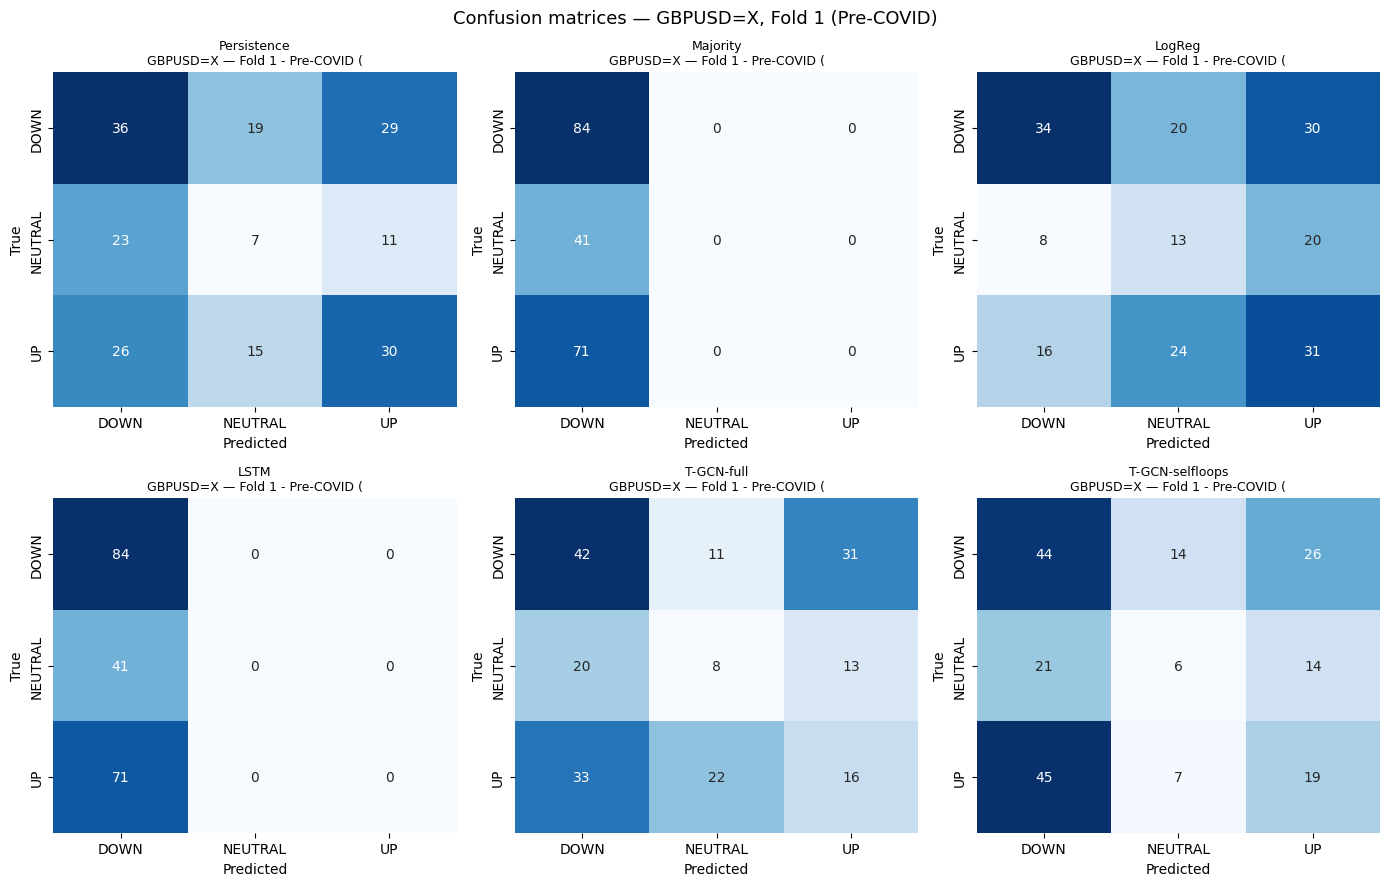

In [7]:
# Confusion matrix all 6 models: GBPUSD=X across Fold 1 (demonstrates LSTM class collapse)

models = ["Persistence", "Majority", "LogReg", "LSTM", "T-GCN-full", "T-GCN-selfloops"]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, model in zip(axes.flat, models):
    plot_confusion(model, "Fold 1 - Pre-COVID (2019)", "GBPUSD=X", ax=ax)
plt.suptitle("Confusion matrices — GBPUSD=X, Fold 1 (Pre-COVID)", fontsize=13)
plt.tight_layout()
plt.savefig("confusion_grid_gbpusd_fold1.png", dpi=150, bbox_inches="tight")
plt.show()

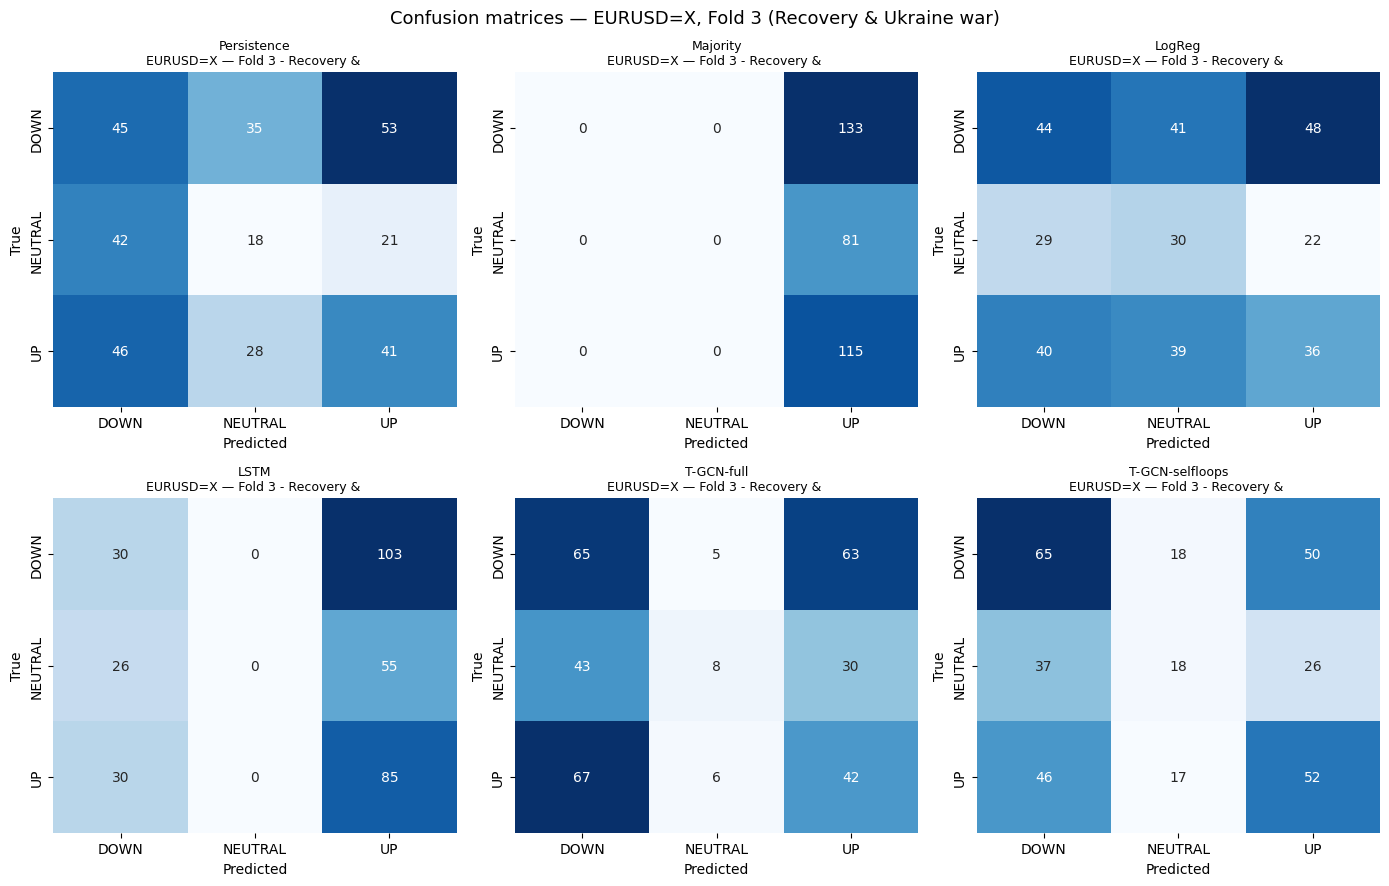

In [8]:
# Confusion matrix all 6 models: EURUSD=X across Fold 3 (typical comparison and no collapse)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, model in zip(axes.flat, models):
    plot_confusion(model, "Fold 3 - Recovery & Ukraine war (2021-Jun 2022)", "EURUSD=X", ax=ax)
plt.suptitle("Confusion matrices — EURUSD=X, Fold 3 (Recovery & Ukraine war)", fontsize=13)
plt.tight_layout()
plt.savefig("confusion_grid_eurusd_fold3.png", dpi=150, bbox_inches="tight")
plt.show()

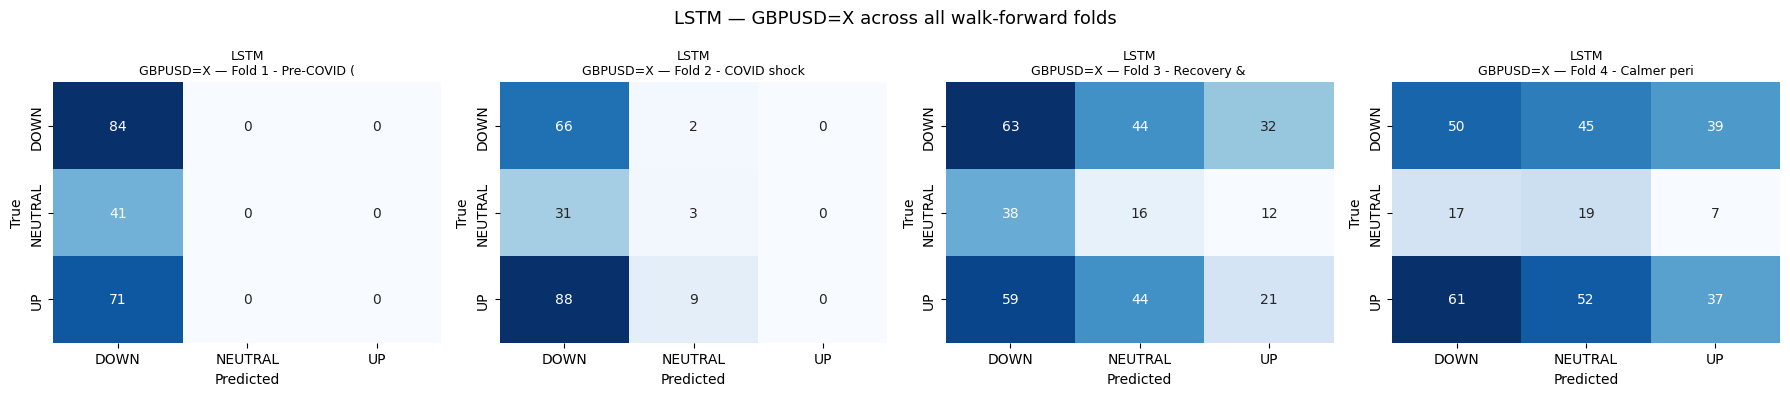

In [9]:
# LSTM across all 4 folds: GBPUSD=X (shows collapse in market-dependent conditions)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, fold in zip(axes, FOLDS):
    plot_confusion("LSTM", fold["name"], "GBPUSD=X", ax=ax)
plt.suptitle("LSTM — GBPUSD=X across all walk-forward folds", fontsize=13)
plt.tight_layout()
plt.savefig("confusion_lstm_gbpusd_allfolds.png", dpi=150, bbox_inches="tight")
plt.show()

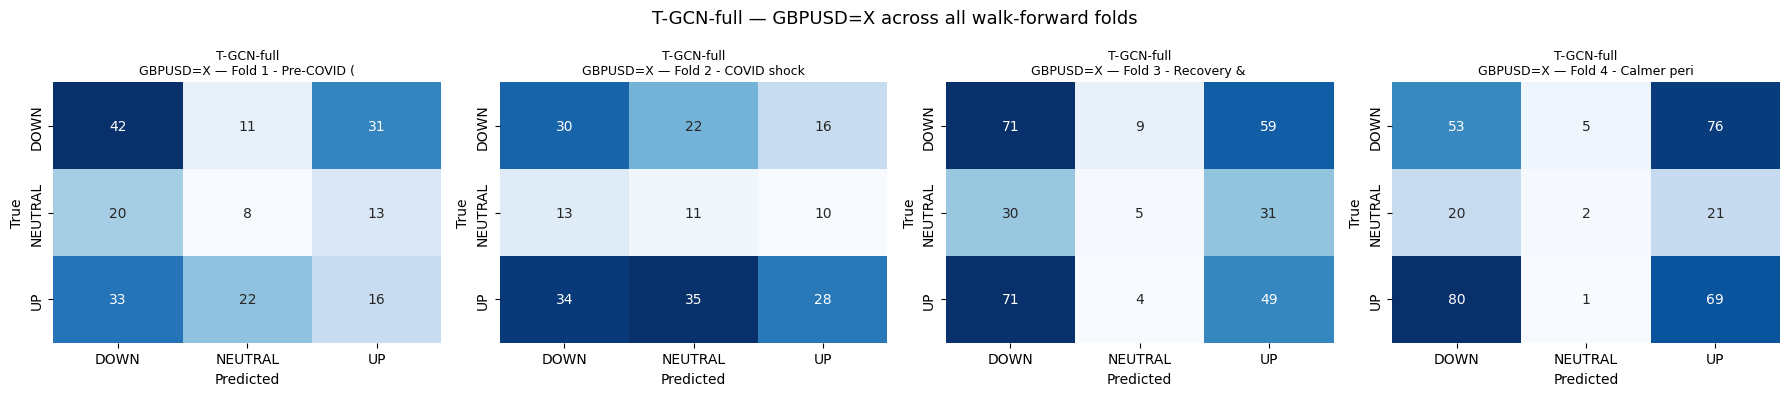

In [10]:
# T-GCN full graph variant across all 4 folds: GBPUSD=X (shows stable class output)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, fold in zip(axes, FOLDS):
    plot_confusion("T-GCN-full", fold["name"], "GBPUSD=X", ax=ax)
plt.suptitle("T-GCN-full — GBPUSD=X across all walk-forward folds", fontsize=13)
plt.tight_layout()
plt.savefig("confusion_tgcnfull_gbpusd_allfolds.png", dpi=150, bbox_inches="tight")
plt.show()

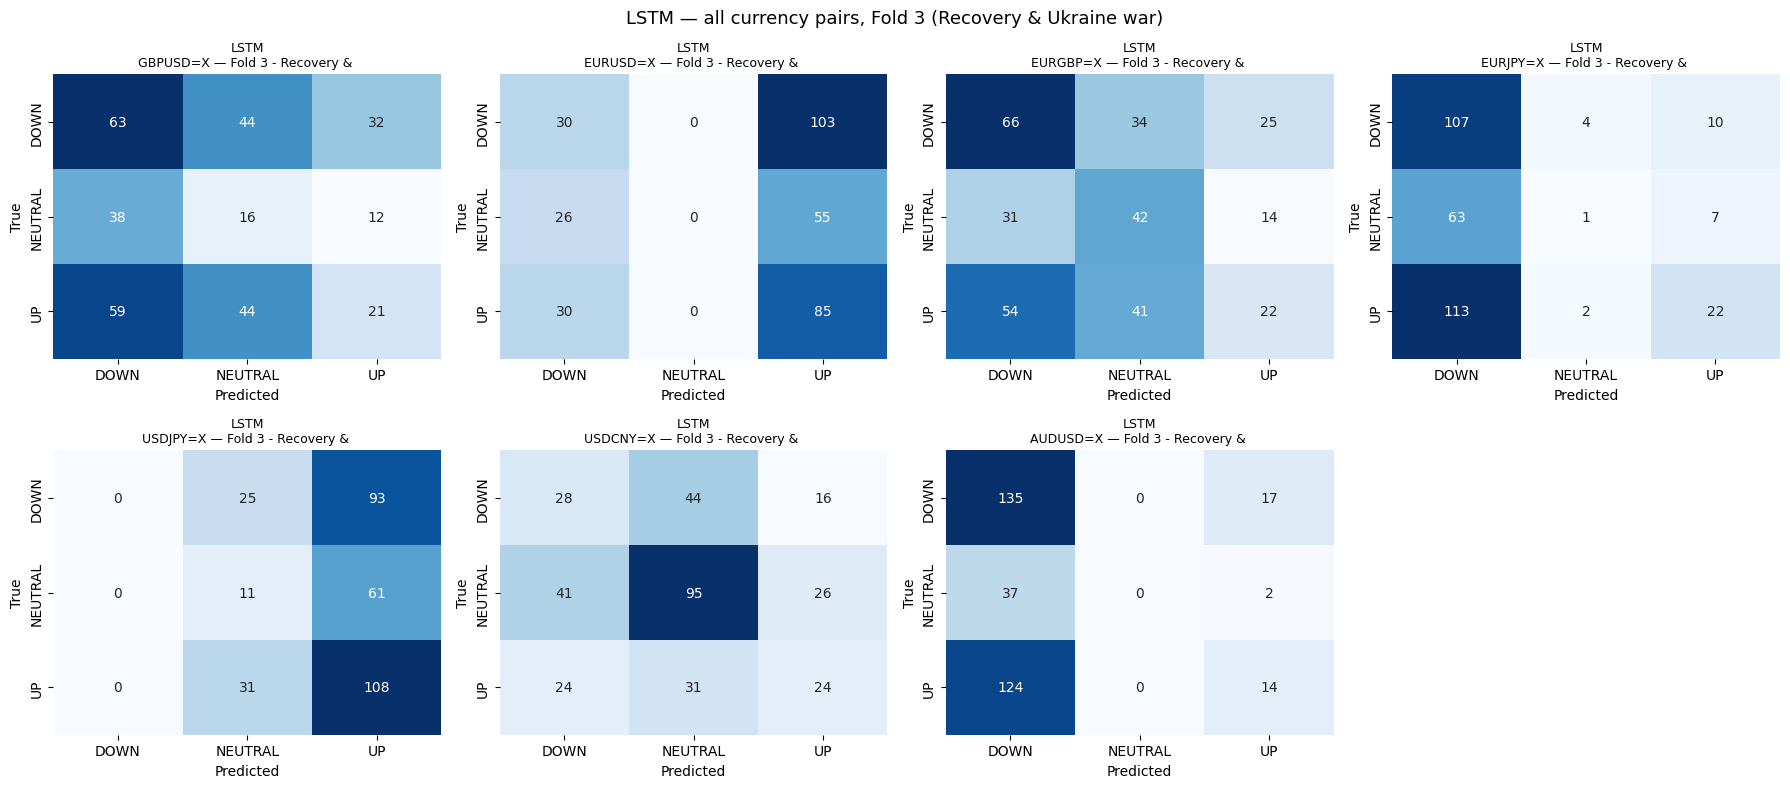

In [11]:
# LSTM confusion matrix grid: All 7 pairs across Fold 3 (shows per-pair collapse patterns)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, pair in zip(axes.flat, pair_list):
    plot_confusion("LSTM", "Fold 3 - Recovery & Ukraine war (2021-Jun 2022)", pair, ax=ax)
axes.flat[-1].axis("off")
plt.suptitle("LSTM — all currency pairs, Fold 3 (Recovery & Ukraine war)", fontsize=13)
plt.tight_layout()
plt.savefig("confusion_lstm_allpairs_fold3.png", dpi=150, bbox_inches="tight")
plt.show()

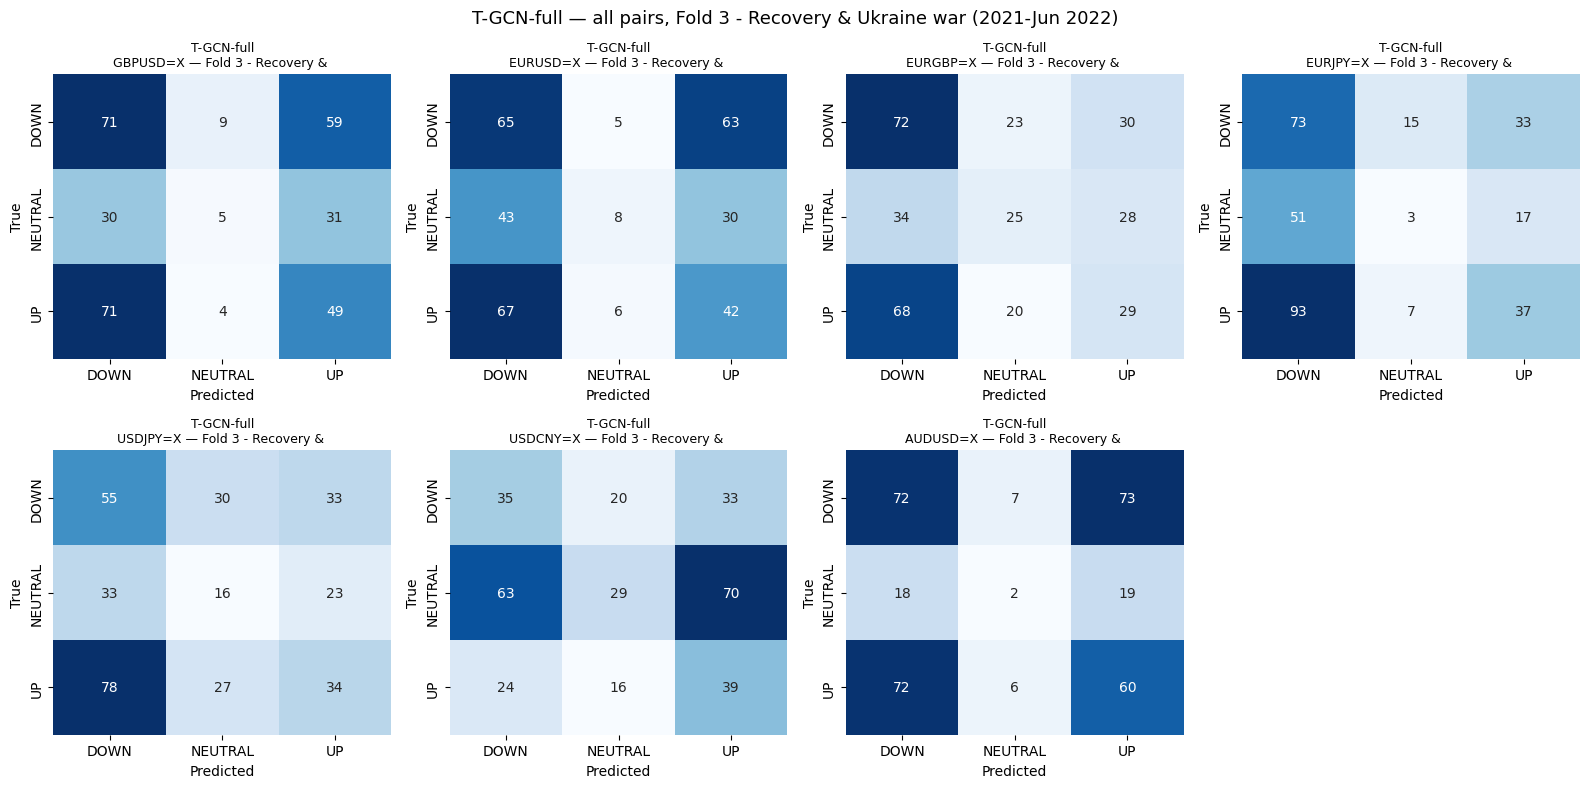

In [12]:
# T-GCN full graph confusion matrix grid: All 7 pairs across Fold 3 (shows class outputs)

MODEL_TO_TRACK = "T-GCN-full"
FOLD_TO_TRACK = "Fold 3 - Recovery & Ukraine war (2021-Jun 2022)"

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, pair in zip(axes.flat, pair_list):
    plot_confusion(MODEL_TO_TRACK, FOLD_TO_TRACK, pair, ax=ax)
axes.flat[-1].axis("off")
plt.suptitle(f"{MODEL_TO_TRACK} — all pairs, {FOLD_TO_TRACK}", fontsize=13)
plt.tight_layout()
plt.savefig("confusion_tgcnfull_allpairs.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# Defines Loss curve plotting function: For T-GCN variants and LSTM

def plot_loss_curve(model_type, fold_name, key, ax=None):
    """model_type: 'LSTM' or 'T-GCN'. key: pair name (LSTM) or variant name (T-GCN)."""
    train_loss, val_loss = preds_data["loss_histories"][model_type][fold_name][key]
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 3.5))
    epochs = range(1, len(train_loss) + 1)
    ax.plot(epochs, train_loss, label="Train loss", marker="o", markersize=3)
    ax.plot(epochs, val_loss, label="Val loss", marker="o", markersize=3)
    ax.set_title(f"{model_type} — {key}\n{fold_name[:25]}", fontsize=9)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend(fontsize=8)
    return ax

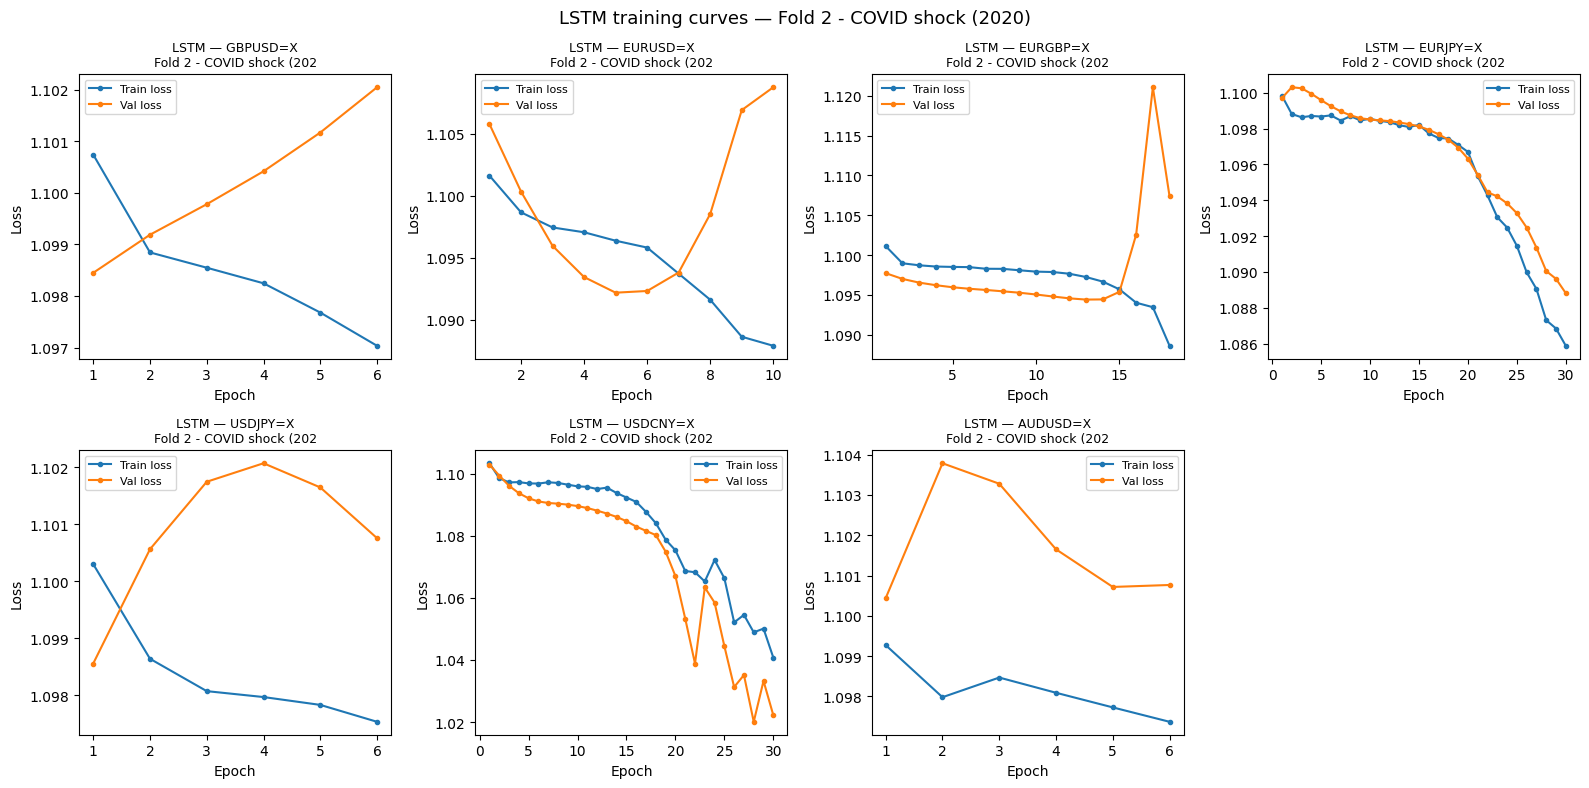

In [14]:
# LSTM loss curves: All 7 pairs across FOLD 2

FOLD_TO_TRACK = "Fold 2 - COVID shock (2020)"

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, pair in zip(axes.flat, pair_list):
    plot_loss_curve("LSTM", FOLD_TO_TRACK, pair, ax=ax)
axes.flat[-1].axis("off")
plt.suptitle(f"LSTM training curves — {FOLD_TO_TRACK}", fontsize=13)
plt.tight_layout()
plt.savefig("loss_lstm_allpairs.png", dpi=150, bbox_inches="tight")
plt.show()

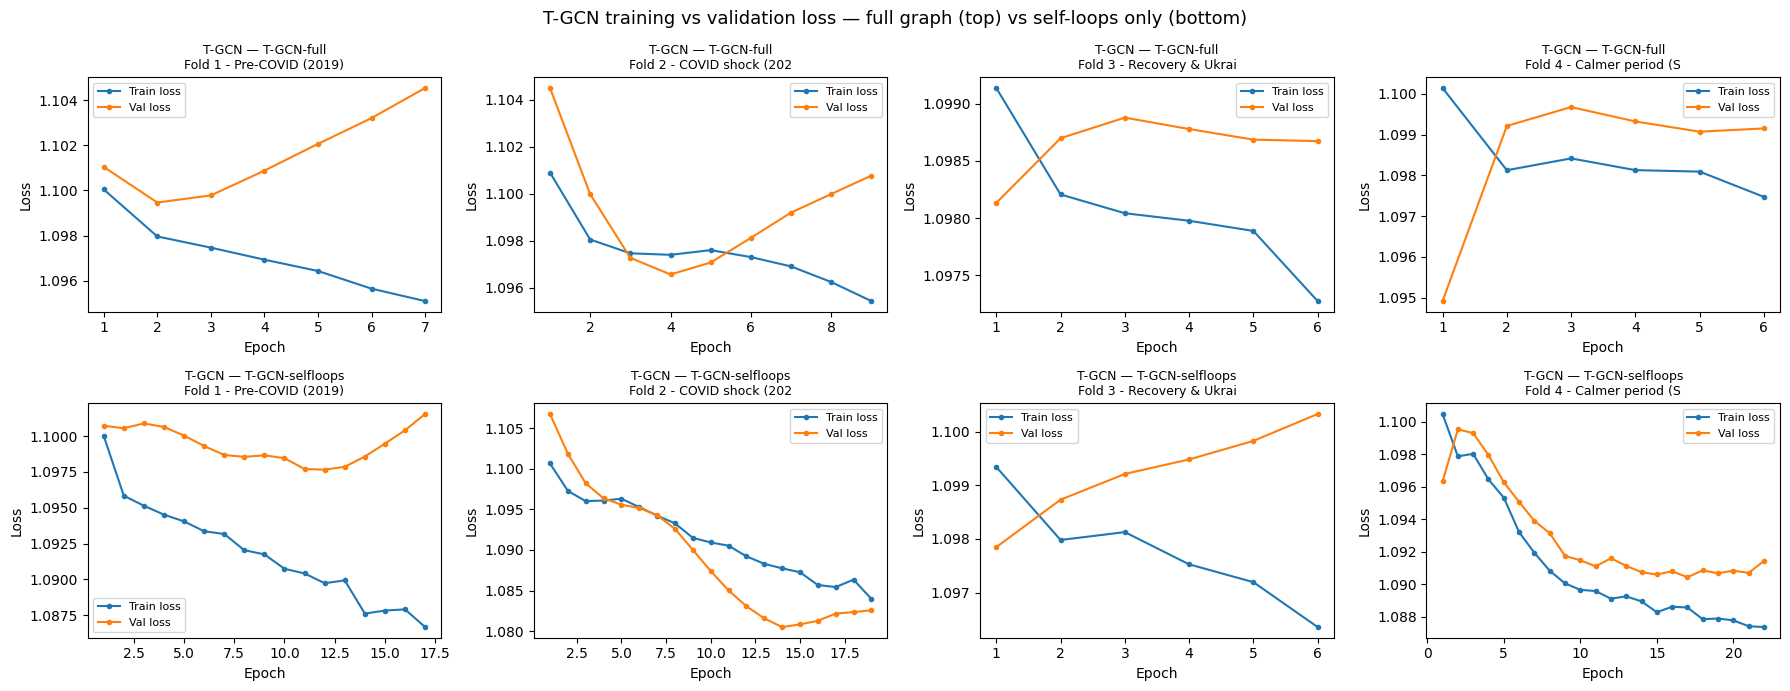

In [15]:
# T-GCN loss curves — both variants across all 4 folds
# Top row: T-GCN-full, Bottom row: T-GCN-selfloops


fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for col, fold in enumerate(FOLDS):
    plot_loss_curve("T-GCN", fold["name"], "T-GCN-full", ax=axes[0, col])
    plot_loss_curve("T-GCN", fold["name"], "T-GCN-selfloops", ax=axes[1, col])
plt.suptitle("T-GCN training vs validation loss — full graph (top) vs self-loops only (bottom)", fontsize=13)
plt.tight_layout()
plt.savefig("loss_tgcn_variants_allfolds.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# Main results table: Mean macro-F1 per model per fold

wf_nopooled = wf[wf["pair"] != "ALL (pooled)"].copy()

summary_table = wf_nopooled.pivot_table(
    index="fold", columns="model", values="test_macro_f1", aggfunc="mean"
)
model_order = ["Persistence", "Majority", "LogReg", "LSTM", "T-GCN-full", "T-GCN-selfloops"]
summary_table = summary_table[model_order].round(4)

summary_table.loc["All folds (mean)"] = wf_nopooled.groupby("model")["test_macro_f1"].mean()[model_order].round(4)

print(summary_table.to_string())
summary_table.to_csv("summary_macro_f1_table.csv")

model                                            Persistence  Majority  LogReg    LSTM  T-GCN-full  T-GCN-selfloops
fold                                                                                                               
Fold 1 - Pre-COVID (2019)                             0.3287    0.1798  0.3557  0.2745      0.3258           0.3369
Fold 2 - COVID shock (2020)                           0.3357    0.1822  0.3175  0.2968      0.2913           0.3172
Fold 3 - Recovery & Ukraine war (2021-Jun 2022)       0.3245    0.1880  0.3259  0.2930      0.3106           0.3427
Fold 4 - Calmer period (Sep 2022-2023)                0.3347    0.1896  0.3162  0.3118      0.3187           0.3186
All folds (mean)                                      0.3309    0.1849  0.3288  0.2940      0.3116           0.3289


In [17]:
# Pairwise dominance comparison across all pair-fold combinations: how often each model wins per pair-fold matchup

deep = wf_nopooled[wf_nopooled["model"].isin(["LSTM", "T-GCN-full", "T-GCN-selfloops"])]
pivot = deep.pivot_table(index=["fold", "pair"], columns="model", values="test_macro_f1")
pivot["best"] = pivot.idxmax(axis=1)

win_counts = pivot["best"].value_counts()
print("Win counts across 28 pair-fold matchups:")
print(win_counts.to_string())

# Deep model performance against baseline thresholds: Persistence, Logistic Regression & Majority
print("\nBeats Persistence:")
all_piv = wf_nopooled.pivot_table(index=["fold", "pair"], columns="model", values="test_macro_f1")
for m in ["LSTM", "T-GCN-full", "T-GCN-selfloops"]:
    beats = (all_piv[m] > all_piv["Persistence"]).sum()
    print(f"  {m}: {beats}/28")

print("\nBeats LogReg:")
for m in ["LSTM", "T-GCN-full", "T-GCN-selfloops"]:
    beats = (all_piv[m] > all_piv["LogReg"]).sum()
    print(f"  {m}: {beats}/28")


print("\nBeats Majority:")
for m in ["LSTM", "T-GCN-full", "T-GCN-selfloops"]:
    beats = (all_piv[m] > all_piv["Majority"]).sum()
    print(f"  {m}: {beats}/28")

Win counts across 28 pair-fold matchups:
best
T-GCN-selfloops    16
T-GCN-full          6
LSTM                6

Beats Persistence:
  LSTM: 8/28
  T-GCN-full: 9/28
  T-GCN-selfloops: 13/28

Beats LogReg:
  LSTM: 11/28
  T-GCN-full: 10/28
  T-GCN-selfloops: 14/28

Beats Majority:
  LSTM: 27/28
  T-GCN-full: 28/28
  T-GCN-selfloops: 28/28


In [18]:
# Per-class F1 breakdown: Across all 6 models

per_class_table = dm_full.groupby("model")[["f1_DOWN", "f1_NEUTRAL", "f1_UP", "accuracy", "precision_macro", "recall_macro"]].mean()
per_class_table = per_class_table.reindex(model_order).round(4)

print(per_class_table.to_string())
per_class_table.to_csv("per_class_f1_table.csv")

                 f1_DOWN  f1_NEUTRAL   f1_UP  accuracy  precision_macro  recall_macro
model                                                                                
Persistence       0.3667      0.2308  0.3953    0.3656           0.3309        0.3309
Majority          0.3397      0.0616  0.1534    0.3854           0.1285        0.3333
LogReg            0.3561      0.2568  0.3736    0.3401           0.3406        0.3409
LSTM              0.3758      0.2129  0.2852    0.3776           0.2977        0.3483
T-GCN-full        0.3749      0.1850  0.3746    0.3503           0.3350        0.3343
T-GCN-selfloops   0.3826      0.2216  0.3880    0.3666           0.3495        0.3536


In [19]:
# Per-class F1 by fold: Across all 6 models

per_class_by_fold = dm_full.groupby(["fold", "model"])[["f1_DOWN", "f1_NEUTRAL", "f1_UP"]].mean().round(4)
per_class_by_fold = per_class_by_fold.reindex(model_order, level="model")
print(per_class_by_fold.to_string())

                                                                 f1_DOWN  f1_NEUTRAL   f1_UP
fold                                            model                                       
Fold 1 - Pre-COVID (2019)                       Persistence       0.3420      0.2697  0.3746
                                                Majority          0.4000      0.0000  0.1393
                                                LogReg            0.3787      0.2878  0.4006
                                                LSTM              0.4105      0.2161  0.1664
                                                T-GCN-full        0.4222      0.1957  0.3525
                                                T-GCN-selfloops   0.4147      0.2797  0.3411
Fold 2 - COVID shock (2020)                     Persistence       0.3836      0.2214  0.4022
                                                Majority          0.3078      0.0841  0.1549
                                                LogReg            0.36

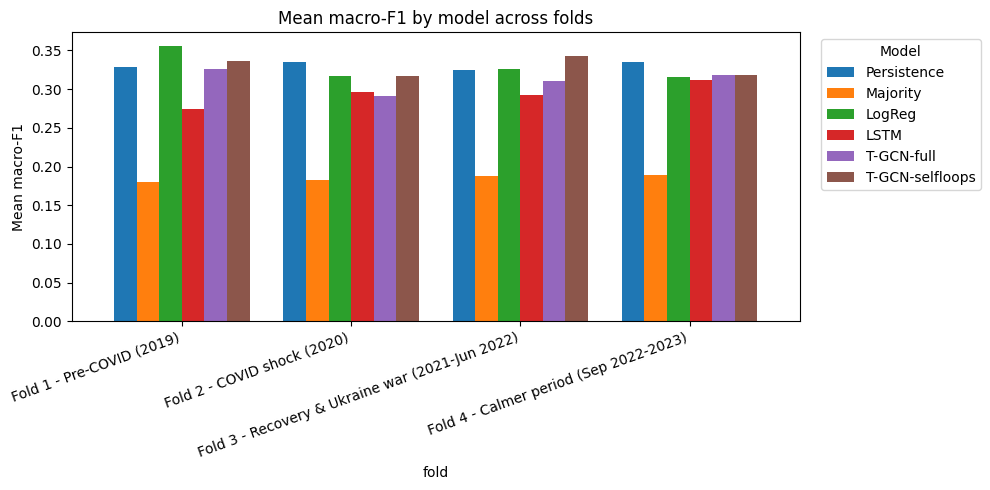

In [20]:
# Bar chart: Fold level macro F1 comparison across all models

fig, ax = plt.subplots(figsize=(10, 5))
plot_data = summary_table.drop("All folds (mean)")  # exclude the summary row
plot_data.plot(kind="bar", ax=ax, width=0.8)
ax.set_ylabel("Mean macro-F1")
ax.set_title("Mean macro-F1 by model across folds")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xticklabels(plot_data.index, rotation=20, ha="right")
plt.tight_layout()
plt.savefig("bar_f1_by_fold.png", dpi=150, bbox_inches="tight")
plt.show()

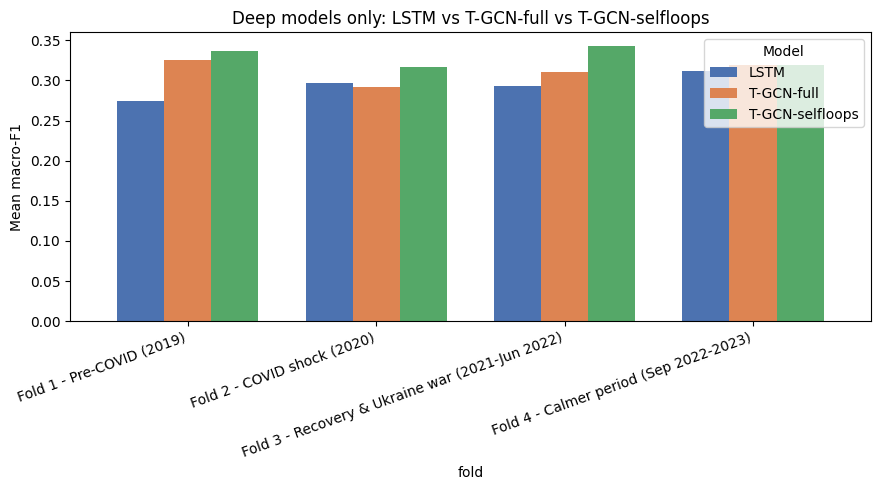

In [21]:
# Bar chart: Deep model macro-F1 comparison across walk-forward folds
# LSTM vs T-GCN-full vs T-GCN-selfloops only

deep_summary = summary_table[["LSTM", "T-GCN-full", "T-GCN-selfloops"]].drop("All folds (mean)")

fig, ax = plt.subplots(figsize=(9, 5))
deep_summary.plot(kind="bar", ax=ax, width=0.75, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylabel("Mean macro-F1")
ax.set_title("Deep models only: LSTM vs T-GCN-full vs T-GCN-selfloops")
ax.set_xticklabels(deep_summary.index, rotation=20, ha="right")
ax.legend(title="Model")
plt.tight_layout()
plt.savefig("bar_deep_models_only.png", dpi=150, bbox_inches="tight")
plt.show()

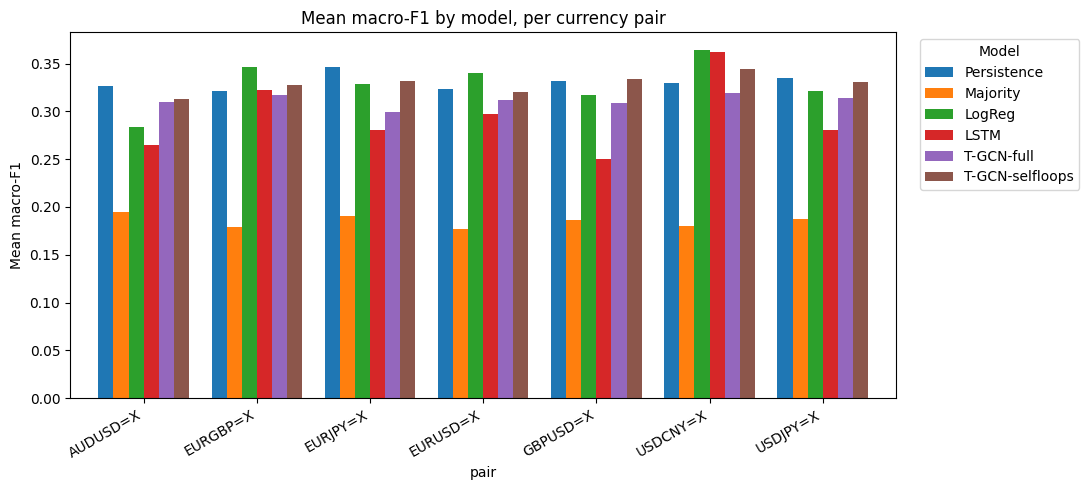

In [22]:
# Bar chart: Per-pair mean macro-F1 (averaged across folds) across all models

per_pair_summary = wf_nopooled.pivot_table(index="pair", columns="model", values="test_macro_f1", aggfunc="mean")
per_pair_summary = per_pair_summary[model_order].round(4)

fig, ax = plt.subplots(figsize=(11, 5))
per_pair_summary.plot(kind="bar", ax=ax, width=0.8)
ax.set_ylabel("Mean macro-F1")
ax.set_title("Mean macro-F1 by model, per currency pair")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xticklabels(per_pair_summary.index, rotation=30, ha="right")
plt.tight_layout()
plt.savefig("bar_f1_by_pair.png", dpi=150, bbox_inches="tight")
plt.show()

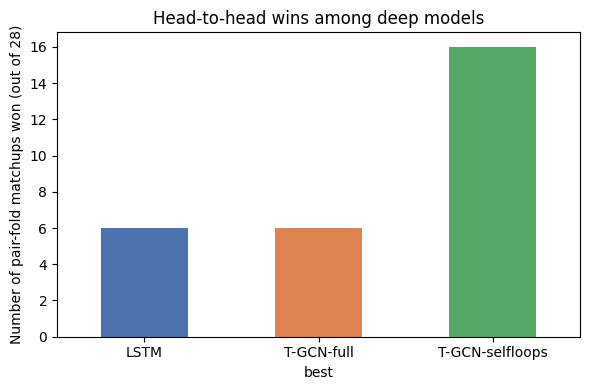

In [23]:
# Pairwise dominance visualisation: LSTM, T-GCN self loops & T-GCN full graph win distribution


fig, ax = plt.subplots(figsize=(6, 4))
win_counts.reindex(["LSTM", "T-GCN-full", "T-GCN-selfloops"]).plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set_ylabel("Number of pair-fold matchups won (out of 28)")
ax.set_title("Head-to-head wins among deep models")
ax.set_xticklabels(["LSTM", "T-GCN-full", "T-GCN-selfloops"], rotation=0)
plt.tight_layout()
plt.savefig("bar_win_counts.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
# Wilcoxon signed rank test for statistical significance of model performance difference:
# Across 28 matched pair-fold comparisons

from scipy.stats import wilcoxon

lstm_scores = pivot["LSTM"].values
tgcn_full_scores = pivot["T-GCN-full"].values
tgcn_self_scores = pivot["T-GCN-selfloops"].values

print("LSTM vs T-GCN-full:")
stat, p = wilcoxon(lstm_scores, tgcn_full_scores)
print(f"  statistic={stat:.4f}, p-value={p:.4f}")

print("\nLSTM vs T-GCN-selfloops:")
stat, p = wilcoxon(lstm_scores, tgcn_self_scores)
print(f"  statistic={stat:.4f}, p-value={p:.4f}")

print("\nT-GCN-full vs T-GCN-selfloops:")
stat, p = wilcoxon(tgcn_full_scores, tgcn_self_scores)
print(f"  statistic={stat:.4f}, p-value={p:.4f}")

print("\n(p < 0.05 suggests the difference in macro-F1 across the 28 pair-fold matchups is unlikely to be due to chance)")

LSTM vs T-GCN-full:
  statistic=121.0000, p-value=0.0628

LSTM vs T-GCN-selfloops:
  statistic=87.0000, p-value=0.0071

T-GCN-full vs T-GCN-selfloops:
  statistic=84.0000, p-value=0.0116

(p < 0.05 suggests the difference in macro-F1 across the 28 pair-fold matchups is unlikely to be due to chance)
